# 1.	Define the main goal for the geodemographic classification (marketing, retail and service planning).

| Variable | Census file | Purpose | Topic |
|---|---|---|---|
| Age structure     | KS102SC | Identify age differences   | Socio-demographics  |
| Car availability  | KS404SC | Identify car ownership     | Housing             |
| Economic activity | KS601SC | Identify employment levels | Economics           |
| Travel to work    | QS701SC | Understand existing commuting patterns and transport modes | Transport  |
| Qualifications    | KS501SC | Provide an additional socioeconomic characteristic         | Education  |

Service planning, specifically where may benefit from bus routes and public transit within Edinburgh, helping people get around and reducing traffic congestion within inner city from cars.


In [1]:
import pandas as pd
import os

csv_directory = "."

csv_files = [file for file in os.listdir(csv_directory) if file.endswith(".csv")]


merged_data = pd.DataFrame()


for csv_file in csv_files:
    csv_path = os.path.join(csv_directory, csv_file)
    df_csv = pd.read_csv(csv_path, skiprows=4, low_memory=False)
    
    merged_data = pd.concat([merged_data, df_csv], axis=1)


merged_data.to_csv("merged_census_data.csv", index=False)

#Replicated pathway step and data acquisition 
#SkipRows 4 added in due to first 4 rows in cvs being blank and it causing data issues. 

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Assignment2\\Lab6'

In [ ]:
import pandas as pd
import geopandas as gpd

shp_path = ("output-area-2011-eor/OutputArea2011_EoR.shp")
gdf = gpd.read_file(shp_path)

csv_path = "merged_census_data.csv"
csv_data = pd.read_csv(csv_path, low_memory=False)

merged_data = gdf.merge(csv_data, left_on='code', right_on='Unnamed: 0', how='left')

#Replicating code again however subsituting OA Glasgow areas with AO areas for the whole of Scotland as thats all I could I find
#Utalising our new csv merged census data 

In [ ]:
gdf.head
#Seeing if merge etc went through 

In [ ]:
merged_data.columns
#Looking at what column I can specify to be Edinburgh 

In [ ]:
merged_data = merged_data[merged_data["council"] == "S12000036"]
#Chosen council with the code for Edinburgh selected
#Did a similar process in a previous lab with Dundee

In [ ]:
print(merged_data["council"].unique())
print(merged_data["council"].value_counts(dropna=False))

In [ ]:
merged_data = merged_data.dropna()
merged_data.info()

In [ ]:
merged_data.explore()
#Success!
#Now I can progress with steps

In [ ]:
list(merged_data.columns)

In [ ]:
merged_data.info()

In [ ]:
merged_data.shape

In [ ]:
merged_data.head()

In [ ]:
merged_data['Economically active: Employee: Full-time'].describe()

In [ ]:
merged_data.Popcount.describe()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

attributes_to_plot = ['Number of cars or vans in household: No cars or vans',
                      'Economically active: Employee: Full-time',
                      'Bus, minibus or coach',
                      'Economically active: Full-time student']

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.violinplot(x=merged_data[attribute])
    plt.title(attribute)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

#Exploring potential variables I could use with replicated code.

In [ ]:
import matplotlib.pyplot as plt

attributes_to_plot = ['Number of cars or vans in household: No cars or vans',
                      'Economically active: Employee: Full-time',
                      'Bus, minibus or coach',
                      'Economically active: Full-time student']

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.histplot(merged_data[attribute].astype(str), kde=True)
    plt.title(attribute)

plt.tight_layout()
plt.show()

#Changed this a couple times to see how often variables came up, playing around with code.

1. Education
2. Age Range
3. Transport
4. Economics
5. Housing

In [ ]:
def calculate_percentages(dataframe, total_columns, value_columns):

    result_df = pd.DataFrame()

    for total_col, value_col in zip(total_columns, value_columns):
        percentage_col_name = f"{value_col}_percentage"

        if total_col not in dataframe.columns:
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")
 
        dataframe[value_col] = pd.to_numeric(dataframe[value_col], errors='coerce')
        dataframe[total_col] = pd.to_numeric(dataframe[total_col], errors='coerce')
        
        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100

    return result_df


total_cols = ['All households', 'All households', 'All households',
              'All households.1', 'All households.1',
              'All people aged 16 and over',
              'All people aged 16 to 74', 'All people aged 16 to 74',
              'All people aged 16 to 74.1', 'All people aged 16 to 74.1',
             
             ]

value_cols = ['Rented: Council (Local authority)',
              'Rented: Private landlord or letting agency',
              'Owned: Shared ownership (part owned and part rented)',
              'Number of cars or vans in household: One car or van',
              'Number of cars or vans in household: No cars or vans',
              'Schoolchildren and full-time students: Aged 18 and over',
              'Economically active: Employee: Full-time',
              'Economically inactive: Retired',
              'Passenger in a car or van',
              'Taxi or minicab',
             
             ]


result_dataframe = calculate_percentages(merged_data, total_cols, value_cols)

#Replicated code however substituted with my desired values and variables
#Honestly in hindsight was a bit lost with how and what clustering did,
#therefore, utalised variables based on what I thought would be appropriate from my purposes.

In [ ]:
merged_data.info()

In [ ]:
result_dataframe.head()

In [ ]:
concatenated_df = pd.concat([merged_data, result_dataframe], axis=1, ignore_index=False)
concatenated_df.head()

In [ ]:
list(concatenated_df.columns)

In [ ]:
keep_cols= [
    'code',
    'Popcount',
    'HHcount',
    'council',
    'geometry',
    'Rented: Council (Local authority)_percentage',
    'Rented: Private landlord or letting agency_percentage',
    'Owned: Shared ownership (part owned and part rented)_percentage',
    'Number of cars or vans in household: One car or van_percentage',
    'Number of cars or vans in household: No cars or vans_percentage',
    'Schoolchildren and full-time students: Aged 18 and over_percentage',
    'Economically active: Employee: Full-time_percentage',
    'Economically inactive: Retired_percentage',
    'Passenger in a car or van_percentage',
    'Taxi or minicab_percentage',
]

edinburgh_census_data = concatenated_df[keep_cols]

#Again replicating code, subsetting attributes to be percentages 
#Ensuring I am also keeping my geometry and code information etc. 

In [ ]:
edinburgh_census_data.head()

In [ ]:
short_column_names = {
    'Rented: Council (Local authority)_percentage': 'Council Rented',
    'Rented: Private landlord or letting agency_percentage': 'Privately Rented',
    'Owned: Shared ownership (part owned and part rented)_percentage': 'Part Rented',
    'Number of cars or vans in household: One car or van_percentage': 'One Car/Van',
    'Number of cars or vans in household: No cars or vans_percentage': 'No Car/Van',
    'Schoolchildren and full-time students: Aged 18 and over_percentage': 'Full time Student 18+',
    'Economically active: Employee: Full-time_percentage': 'Full time Employee',
    'Economically inactive: Retired_percentage': 'Retired',
    'Passenger in a car or van_percentage': 'Passenger wrk trvl',
    'Taxi or minicab_percentage': 'Taxi wrk trvl',
}

edinburgh_census_data = glasglow_census_data.rename(columns=short_column_names)

#As said shortening to what I thought was appropriate for easier analysis later.

In [ ]:
edinburgh_census_data.head()

In [ ]:
edinburgh_census_data.info()

In [ ]:
numeric_columns = edinburgh_census_data.select_dtypes(include='float64')
z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)
z_score_df.head()

#Replicating again, scaling data so every feature has a mean of 0 and a standard deviation of 1, (I believe).

In [ ]:
z_score_df.shape

In [ ]:
corr = z_score_df.corr()
corr.style.background_gradient(cmap='coolwarm')

#Measuring collinear varaibles which would just convcey similar messages which you will see I have 

In [ ]:
import matplotlib.pyplot as plt

plt.matshow(z_score_df.corr())
plt.show()

In [ ]:
threshold = 0.7 

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated, cmap='coolwarm', cbar=False, annot=True)

plt.title('Highly Correlated Variables')
plt.show()
#As you can see, one car and no car are overlapping in what kind of data they are giving, so going to remove one car and keep no car. 

In [ ]:
z_score_df.info()

In [ ]:
z_score_df.drop(['One Car/Van'], axis=1, inplace=True)
z_score_df.info
#Removed!

In [ ]:
contains_nan = z_score_df.isna().any().any()

if contains_nan:
    print("DataFrame contains NaN values.")
else:
    print("DataFrame does not contain NaN values")
#Got a lot of NaN so this step was important in ensuring data is clean
#I could have redone the same line after for reproducability, but when I have ran this step again immediately after the next step, it succeeds, so didn't feel was necessary. 

In [ ]:
z_score_df.fillna(z_score_df.mean(), inplace=True)
#Imputation method to replace NaN with best estimated guesses based on the rest of the data.

In [ ]:
z_score_df.head()
#Looking better now.

In [ ]:
#Starting here is where the clustering begins, was important to note this transition when solving issues with code and reproducability. 

In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist, pdist

kmeans = KMeans(n_clusters=10)
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_
z_score_df['Cluster'] = kmeans.labels_
#Importing Kmeans and giving our varuiables a cluster of 10 just to experiment as done in the example. 

In [ ]:
plt.hist(labels)


In [ ]:
import numpy as np
def elbow(dataframe, n):
    kMeansVar = [KMeans(n_clusters=k).fit(dataframe.values) for k in range(1, n)] #making use of list comprehensions.
    centroids = [X.cluster_centers_ for X in kMeansVar]
    k_euclid = [cdist(dataframe.values, cent) for cent in centroids]
    dist = [np.min(ke, axis=1) for ke in k_euclid]
    wcss = [sum(d**2) for d in dist]
    tss = sum(pdist(dataframe.values)**2)/dataframe.values.shape[0]
    bss = tss - wcss
    plt.plot(bss)
    plt.show()
 
elbow(z_score_df,15)

In [ ]:
Sum_of_squared_distances = []

K_range = range(1,15)

for k in K_range:
 km = KMeans(n_clusters=k)
 km = km.fit(z_score_df)
 Sum_of_squared_distances.append(km.inertia_)
    
plt.plot(K_range, Sum_of_squared_distances, 'bx-')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For Optimal k')
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist, pdist

kmeans = KMeans(n_clusters=5)
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_
z_score_df['Cluster'] = kmeans.labels_
#Used Elbow method for finding the optimal number of clusters, 
#Originally I carried out alternative methods also but it just caused complications so decided to keep it simple.
#Chose 5 based on visual assumptions looking at compositions and measures between points and the 'elbow' point. 

In [ ]:
z_score_df.head()

In [ ]:
first_row_centers = z_score_df.iloc[0, :]


num_features = len(first_row_centers)


theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')

ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(z_score_df.columns, rotation=45, ha='right')

plt.show()

#This step and slighlty prior deemed difficult as I struggled with wrapping my head around this graph changing when I reran it.
#Obviously this was because it would then rerun certain aspects, and overwite/go over data twice, not completely sure.
#When running Kernal from beginning all the way through, seems to run well though, I think this is correct.

In [ ]:
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.figure(figsize=(12, 8))

clusters = labels

pca_data = z_score_df.drop(columns=['Cluster'], errors='ignore')

scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(pca_data)

pca = PCA(n_components=2).fit(stand_data_scaled) 
pca_result = pca.transform(stand_data_scaled)


variance_ratio = pca.explained_variance_ratio_


fig = px.scatter(x=pca_result[:, 0], y=pca_result[:, 1], color=clusters,
                 labels={'color': 'Cluster'},
                 
                 opacity=0.7,
                 width=800, 
                 height=800)

plt.tight_layout()
fig.show()

print(f"These two components explain {(variance_ratio.sum()*100):.2f}% of the point variability.")
#This displays a scatter plot and point variability
#Had to adjust this code very slightly ensuring I didnt overwite my Cluster code I had already implemented,
#As well as dropping the cluster column so it wouldnt include it in the graph as it skewed data. 
#Adjustments could be wrong, took me a long time playing around with things to get to a point where I thought it was correct. 
#Based it on visual and outcome elements giving me the response I thought was accurate.

In [ ]:
cluster_input = z_score_df.drop(columns=['Cluster'], errors='ignore').copy()

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(cluster_input)

z_score_df['Cluster'] = clusters

#Utalised drop function again as without it, it caused problems.
#Had to pick a random state number as without it the next steps would not be reproducable as names given to clusters would mix up every time they ran.
#Frankenstied code a little bit from example, largely taken from step 65/68 however.

In [ ]:
cluster_centers = pd.DataFrame(kmeans.cluster_centers_,
    columns=cluster_input.columns)

cluster_centers.head(5)

In [ ]:
cluster_centres_df = pd.DataFrame(kmeans.cluster_centers_, columns=cluster_input.columns)

In [ ]:
for i in range(5):

    values = cluster_centres_df.iloc[i, :]

    theta = np.linspace(0, 2 * np.pi, len(values), endpoint=True)

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
    ax.plot(theta, values, marker='o', label='Centres')
    
    ax.plot(theta, np.zeros_like(values), color='red', linestyle='--', label='Average')

    ax.set_xticks(theta)
    ax.set_xticklabels(cluster_centres_df.columns, rotation=45, ha='right')

    ax.set_title(f'Cluster {i}')

    plt.show()

#Indentations keep the loop running, interesting!
#Range of (5) for our 5 clusters
#Adjusted code from previous example however making it loop for all 5 clusters
#Crucial to the analysis as it allows me to easily identify how each cluster is structured.
#This way it is far easier to name them rather than looking at the map and trying to do it all manually in post.

In [ ]:
cluster_names = {
    0: 'Private Rental Working Neighbourhoods',
    1: 'Established Car-Owning Neighbourhoods',
    2: 'Council Housing Neighbourhoods',
    3: 'Student Rental Neighbourhoods',
    4: 'Retirement-Oriented Neighbourhoods'
}
z_score_df['Cluster_Name'] = z_score_df['Cluster'].map(cluster_names)

z_score_df[['Cluster', 'Cluster_Name']].head()

#I looked at the naming clusters step but didnt really understand it, this way just seemed easier. 
#Gave each Cluster a name based on the previous visual display, then implemented it into the table.
#Taken from the San Diego Stage.

In [ ]:

final_df = glasglow_census_data[[
    'code',
    'Popcount',
    'geometry',
    'Council Rented',
    'Privately Rented',
    'No Car/Van',
    'Full time Student 18+',
    'Full time Employee',
    'Retired'
]].copy()


final_df['Cluster'] = z_score_df['Cluster']


final_df['Cluster_Name'] = final_df['Cluster'].map(cluster_names)


final_df = gpd.GeoDataFrame(final_df, geometry='geometry', crs=glasglow_census_data.crs)

final_df.head()

#Creating the final dataframe that will include everything I need to create the final map.
#Utalised columns from edinburgh census data, the cluster assignments, adding in the assigned names, and then converting it to a GDF

In [ ]:
final_df.explore(
    column='Cluster_Name',
    categorical=True,
    cmap='Set1',
    tiles='OpenStreetMap',
    legend=True,
    tooltip=[
        'code',
        'Cluster_Name',
        'Popcount',
        'Council Rented',
        'Privately Rented',
        'No Car/Van',
        'Full time Student 18+',
        'Full time Employee',
        'Retired'
    ]
)
#Replicated creating final map function to display my clusters.

First map displays my 5 clusters well and can be validated visually as for example, the council housing neighbourhoods align with where deprived areas are within Glasgow, as awell as where student rentals are located etc.
It displays to an extent where could benefit from bus routes or public transport, or where access ammenities is highest conversely. However I believe changing the variables could help more.

## I felt as said in the instructions, that my variable selection and cluster groups could be improved so I have went through the same process again but alterating my chosen variables.

In [ ]:
def calculate_percentages(dataframe, total_columns, value_columns):

    result_df = pd.DataFrame()

    for total_col, value_col in zip(total_columns, value_columns):
        percentage_col_name = f"{value_col}_percentage"

        if total_col not in dataframe.columns:
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")
        # The data have several empty values, so you need to process them, forcing them to be a numeric or NaN value
        dataframe[value_col] = pd.to_numeric(dataframe[value_col], errors='coerce')
        dataframe[total_col] = pd.to_numeric(dataframe[total_col], errors='coerce')
        
        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100

    return result_df

# List of corresponding census totals
total_cols = [
    'All households', 'All households',
    'All households.1',
    'All people aged 16 and over', 'All people aged 16 and over',
    'All people aged 16 to 74', 'All people aged 16 to 74', 'All people aged 16 to 74',
    'All people aged 16 to 74.1', 'All people aged 16 to 74.1'
]

# Selected census variables

value_cols = [
    'Rented: Council (Local authority)',
    'Rented: Private landlord or letting agency',
    'Number of cars or vans in household: No cars or vans',
    'Schoolchildren and full-time students: Aged 18 and over',
    'All people aged 16 and over: No qualifications',
    'Economically active: Employee: Full-time',
    'Economically inactive: Retired',
    'Economically inactive: Long-term sick or disabled',
    'Bus, minibus or coach',
    'On foot'
]

# Calculate percentages
result_dataframe = calculate_percentages(merged_data, total_cols, value_cols)

result_dataframe.head()


In [ ]:
concatenated_df = pd.concat([merged_data, result_dataframe], axis=1, ignore_index=False)
concatenated_df.head()

In [ ]:
keep_cols= [
    'code',
    'Popcount',
    'HHcount',
    'council',
    'geometry',
    'Rented: Council (Local authority)_percentage',
    'Rented: Private landlord or letting agency_percentage',
    'Number of cars or vans in household: No cars or vans_percentage',
    'Schoolchildren and full-time students: Aged 18 and over_percentage',
    'All people aged 16 and over: No qualifications_percentage',
    'Economically active: Employee: Full-time_percentage',
    'Economically inactive: Retired_percentage',
    'Economically inactive: Long-term sick or disabled_percentage',
    'Bus, minibus or coach_percentage',
    'On foot_percentage',
]

glasglow_census_data = concatenated_df[keep_cols]

In [ ]:
short_column_names = {
    'Rented: Council (Local authority)_percentage': 'Council Rntd',
    'Rented: Private landlord or letting agency_percentage': 'Priv Rntd',
    'Number of cars or vans in household: No cars or vans_percentage': 'No Car',
    'Schoolchildren and full-time students: Aged 18 and over_percentage': 'Student 18+',
    'All people aged 16 and over: No qualifications_percentage': '16+ No Qualifications',
    'Economically active: Employee: Full-time_percentage': 'Full time',
    'Economically inactive: Retired_percentage': 'Retired',
    'Economically inactive: Long-term sick or disabled_percentage': 'Disabled/Sick',
    'Bus, minibus or coach_percentage': 'Bus Users',
    'On foot_percentage': 'Walkers',
}

glasglow_census_data = glasglow_census_data.rename(columns=short_column_names)

In [ ]:
numeric_columns = glasglow_census_data.select_dtypes(include='float64')
z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)
z_score_df.head()

In [ ]:
corr = z_score_df.corr()
corr.style.background_gradient(cmap='coolwarm')

In [ ]:
import matplotlib.pyplot as plt

plt.matshow(z_score_df.corr())
plt.show()

In [ ]:
threshold = 0.7 # We can adapt this based on waht we have in our data. Recall the subjetivity issue?
# So if we include .8 then we wont be able to reduce any variables., so I took the threshold to 70%

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated, cmap='coolwarm', cbar=False, annot=True)

plt.title('Highly Correlated Variables')
plt.show()

# The plot will represent  BINARY table 0 for false( out of the threshold) and 1 for above the threshold.
# but I also coloured so it is easier to use and cute :)

In [ ]:
contains_nan = z_score_df.isna().any().any()

if contains_nan:
    print("Oh no :( the DataFrame contains NaN values.")
else:
    print("Wahoo! the dataFrame does not contain NaN values. I'm the best")

In [ ]:
z_score_df.fillna(z_score_df.mean(), inplace=True)

In [ ]:
# Final K-means model with 5 clusters

cluster_input = z_score_df.drop(
    columns=['Cluster'], errors='ignore'
).copy()

kmeans = KMeans(n_clusters=5, random_state=43, n_init=10)

clusters = kmeans.fit_predict(cluster_input)

# Store the final cluster assignments
z_score_df['Cluster'] = clusters

In [ ]:
z_score_df.head()

In [ ]:
first_row_centers = z_score_df.iloc[0, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(z_score_df.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

In [ ]:
# Code based on the example provided here: 
# https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_iris.html#sphx-glr-auto-examples-decomposition-plot-pca-iris-py

import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.figure(figsize=(12, 8))

clusters = z_score_df['Cluster'].to_numpy()

pca_data = z_score_df.drop(columns=['Cluster'], errors='ignore')

scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(pca_data)

# PCA analysys.
pca = PCA(n_components=2).fit(stand_data_scaled) #PCA with 2 components, we can also use 3 components, but for now we will use 2 to make it easier to visualize the clusters.
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

# Create a scatter plot
fig = px.scatter(x=pca_result[:, 0], y=pca_result[:, 1], color=clusters,
                 labels={'color': 'Cluster'},
                 #title='Cluster Plot against 1st 2 Principal Components',
                 opacity=0.7,
                 width=800, 
                 height=800)

plt.tight_layout()
fig.show()

print(f"These two components explain {(variance_ratio.sum()*100):.2f}% of the point variability.")


In [ ]:
cluster_centres = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=cluster_input.columns
)

cluster_centres.head(5)

In [ ]:
for i in range(5):

    values = cluster_centres_df.iloc[i, :]

    theta = np.linspace(0, 2 * np.pi, len(values), endpoint=True)

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
    ax.plot(theta, values, marker='o', label='Centres')
    
    ax.plot(theta, np.zeros_like(values), color='red', linestyle='--', label='Average')

    ax.set_xticks(theta)
    ax.set_xticklabels(cluster_centres_df.columns, rotation=45, ha='right')

    ax.set_title(f'Cluster {i}')

    plt.show()

In [ ]:
cluster_names = {
    0: 'Full Time Working Car-Reliant Neighbourhoods',
    1: 'Student and Active Travel Neighbourhoods',
    2: 'Older and Economically Inactive Neighbourhoods',
    3: 'Deprived and Public Public Transport-Dependent Neighbourhoods',
    4: 'Full Time Working Public Transport-Dependent Neighbourhoods'
}

z_score_df['Cluster_Name'] = z_score_df['Cluster'].map(cluster_names)
z_score_df[['Cluster', 'Cluster_Name']].head()

In [ ]:
final_df = glasglow_census_data[[
    'code',
    'Popcount',
    'geometry',
    'Council Rntd',
    'Priv Rntd',
    'No Car',
    'Student 18+',
    '16+ No Qualifications',
    'Full time',
    'Retired',
    'Disabled/Sick',
    'Bus Users',
    'Walkers',
]].copy()

final_df['Cluster'] = z_score_df['Cluster']

final_df['Cluster_Name'] = final_df['Cluster'].map(cluster_names)

final_df = gpd.GeoDataFrame(final_df, geometry='geometry', crs=glasglow_census_data.crs)

final_df.head()


In [ ]:
final_df.explore(
    column='Cluster_Name',
    categorical=True,
    cmap='Set1',
    tiles='OpenStreetMap',
    legend=True,
    tooltip=[
    'code',
    'Popcount',
    'Council Rntd',
    'Priv Rntd',
    'No Car',
    'Student 18+',
    '16+ No Qualifications',
    'Full time',
    'Retired',
    'Disabled/Sick',
    'Bus Users',
    'Walkers',
    ]
)

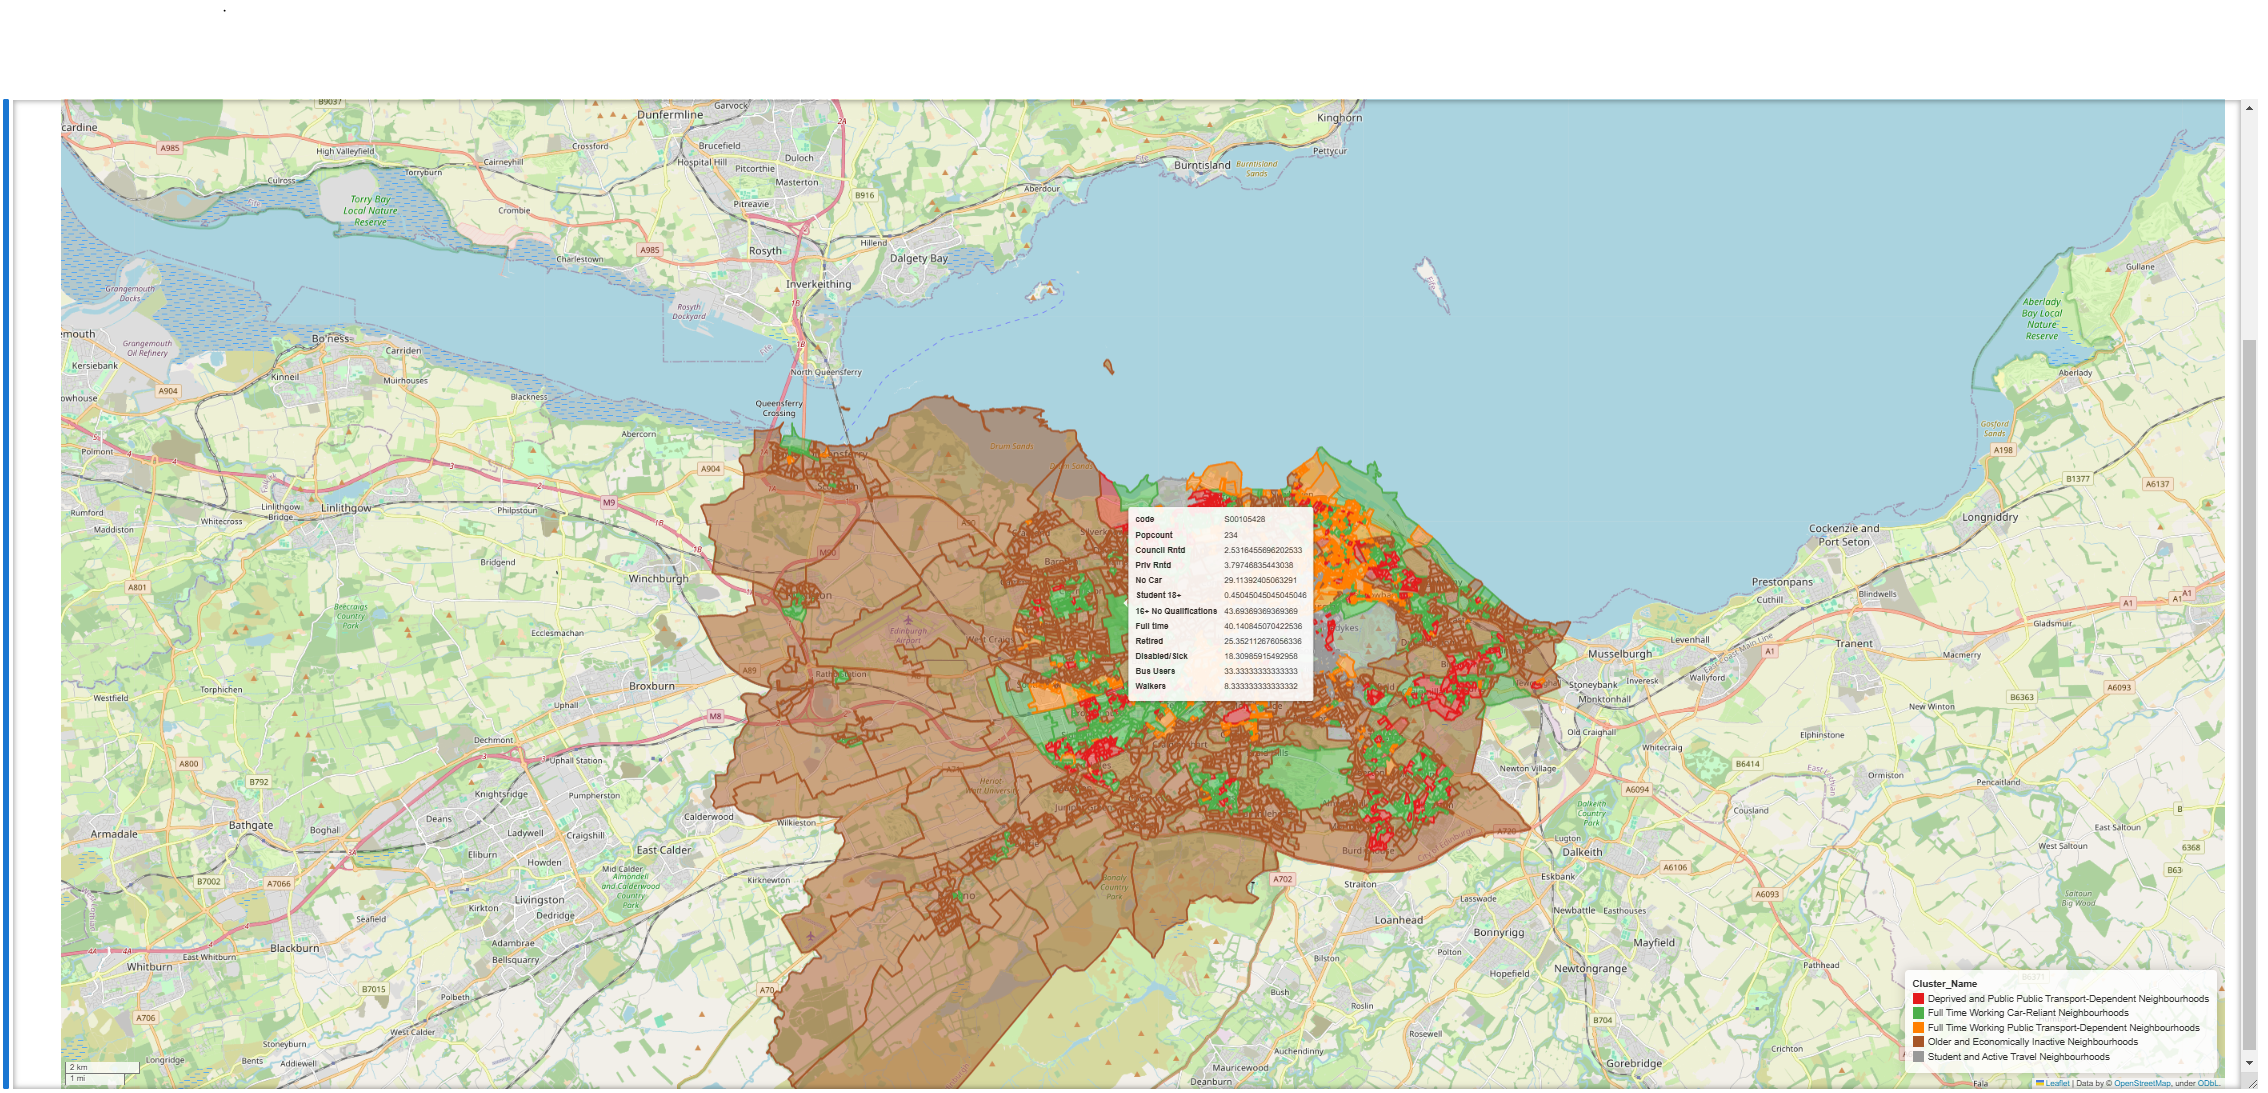

Somewhat similar to the last map however I think these variables and clusters are better defined this time, witnessing public transport dependant and none dependant areas very easily. 


This geodemographic classification technique is subjective as its dependant on the variables I pick and the number of clusters. I tried to reduce the subjectiveness through using variables that were related to service planning as well as over multiple aspects. As well as removing highly correlated variables and only 5 clusters through the Elbow method.
A key challenge was making sure I wasn't overwritng cluster data with re-doing certain parts of code and general errors which popped up throughout. A key part which helped me understand clusters better were the polar plots which identified differences visually very easily.
The classification could help inform public service planning across Edinburgh identifying which neigbourhoods require what needs more. E.g. Full time working public transport reliant neighbourhoods may need increase bus routes and availability for to and from work. 